# Exploring Games

One row per NFL game covered by the tracking data. All data is taken from [here](https://www.kaggle.com/competitions/nfl-big-data-bowl-2027/data). `game_id` links this table to `player_play.csv` and the `game_tracking_*.csv` files.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## games.csv

In [2]:
df = pd.read_csv("../data/games.csv")
df.head().style.format(precision=2).set_caption("First Rows")

,game_id,game_key,season,season_type,week,home_team_abbr,visitor_team_abbr
0,2023090700,59173,2023,REG,1,KC,DET
1,2023091000,59174,2023,REG,1,ATL,CAR
2,2023091001,59175,2023,REG,1,BAL,HOU
3,2023091002,59176,2023,REG,1,CLE,CIN
4,2023091003,59177,2023,REG,1,IND,JAX


In [3]:
print(len(df)) # total number of games in dataset
print(df["season_type"].value_counts())

1002
season_type
REG     816
PRE     147
POST     39
Name: count, dtype: int64


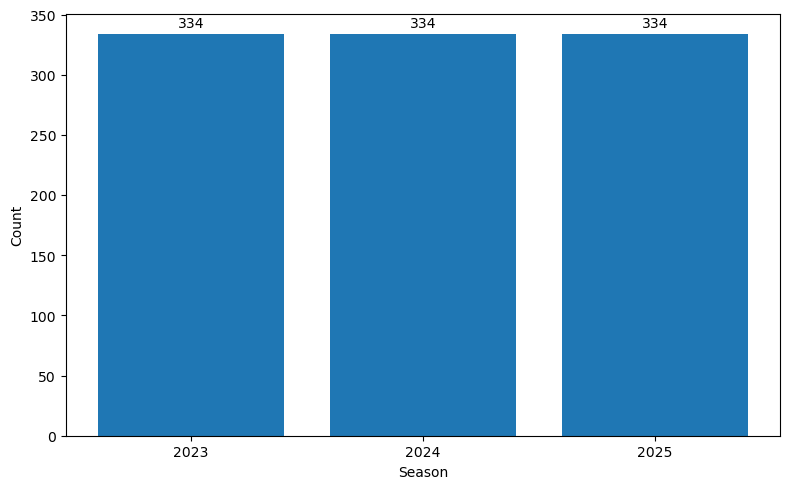

In [4]:
counts = df["season"].value_counts()

fig, ax = plt.subplots(figsize=(8,5))
bars = ax.bar(counts.index.astype(str), counts.values)
ax.bar_label(bars, padding=3)

ax.set_xlabel("Season")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

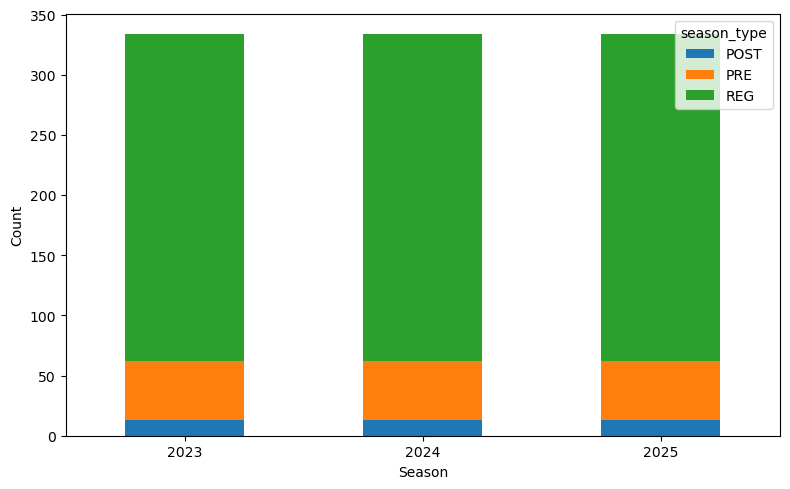

In [5]:
counts = pd.crosstab(df["season"], df["season_type"])

counts.plot.bar(stacked=True, figsize=(8,5), rot=0)
plt.xlabel("Season")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

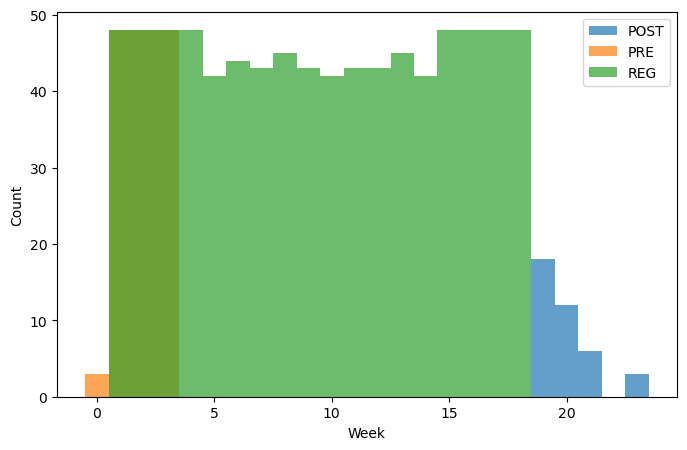

In [6]:
fig, ax = plt.subplots(figsize=(8,5))
for i, (name, g) in enumerate(df.groupby("season_type")):
    ax.hist(g["week"], bins=np.arange(-0.5, 24.5, 1), label=name, color=f"C{i}", alpha=0.7)
ax.set_xlabel("Week")
ax.set_ylabel("Count")
ax.legend()
plt.show()

### Teams

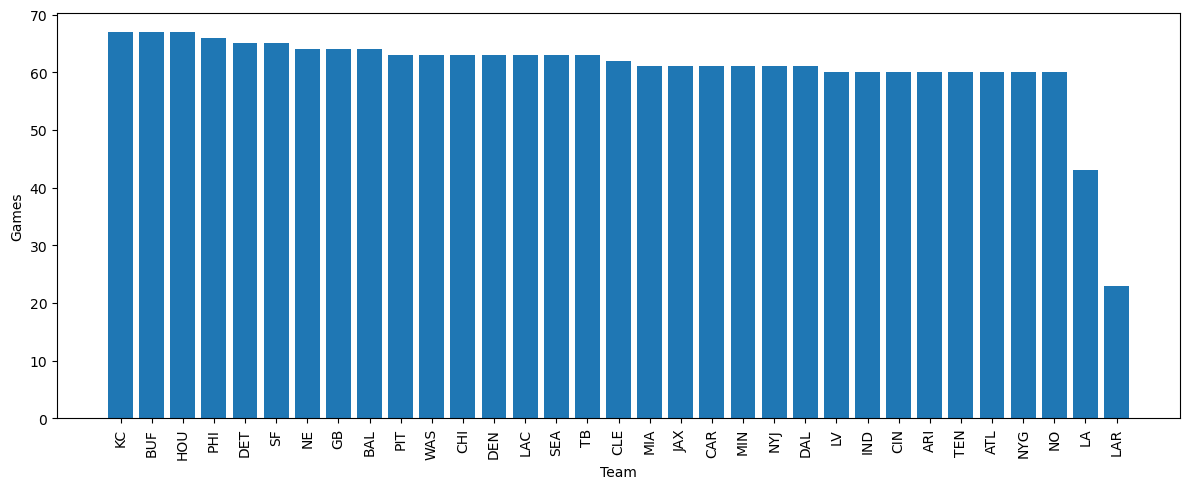

In [7]:
games_per_team = pd.concat([df["home_team_abbr"], df["visitor_team_abbr"]]).value_counts()

fig, ax = plt.subplots(figsize=(12,5))
ax.bar(games_per_team.index, games_per_team.values)
ax.set_xlabel("Team")
ax.set_ylabel("Games")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

Do all games in this file show up in `player_play.csv`?

In [8]:
plays = pd.read_csv("../data/player_play.csv", usecols=["game_id"])
print(df["game_id"].isin(plays["game_id"]).mean())

0.999001996007984
